## Task 1: Dataset Selection and Exploration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, classification_report, confusion_matrix)
import os
import warnings; warnings.filterwarnings('ignore')

In [3]:
path = 'heart.csv'
if not os.path.exists(path):
    try:
        import kagglehub
        folder = kagglehub.dataset_download('fedesoriano/heart-failure-prediction')
        path = os.path.join(folder, 'heart.csv')
    except Exception as e:
        from google.colab import files
        files.upload()
        path = 'heart.csv'

df = pd.read_csv(path)


Using Colab cache for faster access to the 'heart-failure-prediction' dataset.


In [4]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [5]:
print('Shape (rows, columns):', df.shape)
df.info()

Shape (rows, columns): (918, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [6]:
target = 'HeartDisease'
categorical_features = df.select_dtypes(include='object').columns.tolist()
numerical_features = [c for c in df.select_dtypes(exclude='object').columns if c != target]
print('Categorical features:', categorical_features)
print('Numerical features  :', numerical_features)
print('Target variable     :', target)

Categorical features: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Numerical features  : ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
Target variable     : HeartDisease


Missing values per column:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Duplicate records: 0

RestingBP == 0   : 1
Cholesterol == 0 : 172

Summary statistics:


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


Target class distribution:
HeartDisease
1    508
0    410
Name: count, dtype: int64
HeartDisease
1    0.553
0    0.447
Name: proportion, dtype: float64


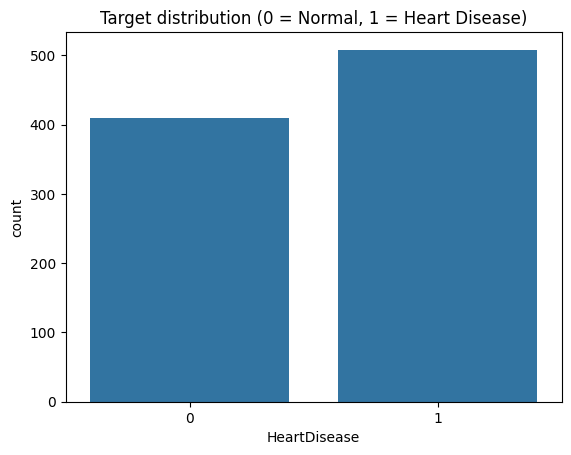

In [7]:
print('Missing values per column:')
print(df.isnull().sum())
print('\nDuplicate records:', df.duplicated().sum())

# Hidden missing values: physiologically impossible zeros
print('\nRestingBP == 0   :', (df['RestingBP'] == 0).sum())
print('Cholesterol == 0 :', (df['Cholesterol'] == 0).sum())

print('\nSummary statistics:')
display(df.describe())

print('Target class distribution:')
print(df[target].value_counts())
print(df[target].value_counts(normalize=True).round(3))
sns.countplot(x=target, data=df)
plt.title('Target distribution (0 = Normal, 1 = Heart Disease)')
plt.show()

### Target variable and problem explanation
The target is **`HeartDisease`** (0 = no heart disease, 1 = heart disease). The model learns from 11 features (age, sex, chest pain type, blood pressure, cholesterol, fasting blood sugar, resting ECG, max heart rate, exercise angina, oldpeak, ST slope) and predicts the class of a new patient. This is a **supervised binary classification** problem.

Note: `.isnull()` reports no missing values, but `RestingBP` and `Cholesterol` contain zeros, which are impossible measurements. They are treated as missing values in Task 2.

## Task 2: Data Preprocessing

In [8]:
df_clean = df.copy()
df_clean[['RestingBP', 'Cholesterol']] = df_clean[['RestingBP', 'Cholesterol']].replace(0, np.nan)
print('Missing values after marking zeros as NaN:')
print(df_clean.isnull().sum()[lambda s: s > 0])

for col in ['RestingBP', 'Cholesterol']:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())
print('\nRemaining missing values:', df_clean.isnull().sum().sum())

Missing values after marking zeros as NaN:
RestingBP        1
Cholesterol    172
dtype: int64

Remaining missing values: 0


In [9]:
before = df_clean.shape[0]
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f'Rows before: {before} | after: {df_clean.shape[0]} | removed: {before - df_clean.shape[0]}')

Rows before: 918 | after: 918 | removed: 0


In [10]:
y = df_clean[target]
X = df_clean.drop(columns=[target])
X = pd.get_dummies(X, columns=categorical_features, drop_first=True, dtype=int)

print('X shape:', X.shape, '| y shape:', y.shape)
print('Target dtype:', y.dtype, '| classes:', sorted(y.unique()))
X.head()

X shape: (918, 15) | y shape: (918,)
Target dtype: int64 | classes: [np.int64(0), np.int64(1)]


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140.0,289.0,0,172,0.0,1,1,0,0,1,0,0,0,1
1,49,160.0,180.0,0,156,1.0,0,0,1,0,1,0,0,1,0
2,37,130.0,283.0,0,98,0.0,1,1,0,0,0,1,0,0,1
3,48,138.0,214.0,0,108,1.5,0,0,0,0,1,0,1,1,0
4,54,150.0,195.0,0,122,0.0,1,0,1,0,1,0,0,0,1


## Task 3: Train-Test Split (80:20, `random_state=42`, stratified)

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print('Training set:', X_train.shape, '| Testing set:', X_test.shape)
print('\nClass proportion in train:', y_train.value_counts(normalize=True).round(3).to_dict())
print('Class proportion in test :', y_test.value_counts(normalize=True).round(3).to_dict())

Training set: (734, 15) | Testing set: (184, 15)

Class proportion in train: {1: 0.553, 0: 0.447}
Class proportion in test : {1: 0.554, 0: 0.446}


## Task 4: Build the Decision Tree Classifier

In [12]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Model trained. First 10 predictions:', y_pred[:10])
print('First 10 actual values            :', y_test.values[:10])
print('Tree depth:', model.get_depth(), '| Leaves:', model.get_n_leaves())

Model trained. First 10 predictions: [1 0 1 1 1 0 0 1 1 1]
First 10 actual values            : [1 1 1 1 0 0 0 1 0 1]
Tree depth: 15 | Leaves: 119


## Task 5: Model Evaluation

In [15]:
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='binary')
rec  = recall_score(y_test, y_pred, average='binary')
f1   = f1_score(y_test, y_pred, average='binary')

print(f'Accuracy : {acc:.4f}')
print(f'Precision: {prec:.4f}')
print(f'Recall   : {rec:.4f}')
print(f'F1-score : {f1:.4f}')
print('\nTraining accuracy:', round(model.score(X_train, y_train), 4))
print('\nClassification Report:\n')
print(classification_report(y_test, y_pred, target_names=['No Heart Disease', 'Heart Disease']))

Accuracy : 0.7772
Precision: 0.7905
Recall   : 0.8137
F1-score : 0.8019

Training accuracy: 1.0

Classification Report:

                  precision    recall  f1-score   support

No Heart Disease       0.76      0.73      0.75        82
   Heart Disease       0.79      0.81      0.80       102

        accuracy                           0.78       184
       macro avg       0.77      0.77      0.77       184
    weighted avg       0.78      0.78      0.78       184



## Task 6: Confusion Matrix

In [ ]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease', 'Disease'],
            yticklabels=['No Disease', 'Disease'])
plt.xlabel('Predicted label'); plt.ylabel('Actual label')
plt.title('Confusion Matrix - Decision Tree')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'True Negatives  (healthy, predicted healthy)      : {tn}')
print(f'False Positives (healthy, predicted disease)      : {fp}')
print(f'False Negatives (disease, predicted healthy)      : {fn}  <- most dangerous error')
print(f'True Positives  (disease, predicted disease)      : {tp}')

### Interpretation of the confusion matrix
- **True Positive (TP):** patients with heart disease correctly flagged, who can be sent for treatment.
- **True Negative (TN):** healthy patients correctly identified, avoiding unnecessary worry and cost.
- **False Positive (FP):** healthy patients wrongly flagged. Result: extra tests and anxiety, but no direct danger.
- **False Negative (FN):** patients with heart disease the model missed. In medicine this is the **most serious error**, since a sick patient may go untreated. Hence **recall** is especially important here.

Compare the printed FP and FN counts: if FN is larger than FP, the model misses more sick patients than it falsely alarms.

## Task 7: Results and Conclusion

,Metric,Score
0,Accuracy,0.7772
1,Precision,0.7905
2,Recall,0.8137
3,F1-score,0.8019


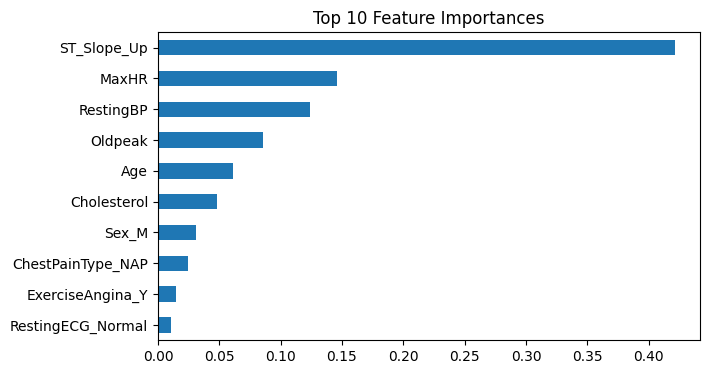

In [22]:
results = pd.DataFrame({'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
                        'Score': [acc, prec, rec, f1]}).round(4)
display(results)
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
imp.head(10).sort_values().plot(kind='barh', figsize=(7, 4), title='Top 10 Feature Importances')
plt.show()

### Performance of the Decision Tree
After running the notebook, copy your numbers into this section. With the default settings, an unpruned tree typically reaches roughly **77-85% accuracy** on this dataset, with a **training accuracy of 100%**. The gap between training and test accuracy shows the model is **overfitting**: it grows until every training sample is memorised. Features such as `ST_Slope`, `ChestPainType`, `Cholesterol`, `MaxHR` and `Oldpeak` usually rank as the most important, which agrees with clinical knowledge.

*(Replace with your actual results: Accuracy = __, Precision = __, Recall = __, F1 = __.)*

### Limitations
1. **Overfitting:** a fully grown tree has high variance. Pruning (`max_depth`, `min_samples_leaf`, `ccp_alpha`) would help.
2. **Small dataset:** only about 900 patients, so the test set is small and scores vary with the split.
3. **Data quality:** many cholesterol values were invalid zeros and were median-imputed, which adds noise.
4. **Single split:** no cross-validation or hyperparameter tuning was used.
5. **Missed patients:** false negatives remain, which is risky for a medical use.
6. The data comes from a limited population, so it may not generalise to other groups.

### Conclusion
The Decision Tree is simple, fast and easy to interpret, and its rules can be explained to doctors. It can serve as a **screening support tool** that flags high-risk patients for further examination, helping hospitals prioritise tests. It should assist, not replace, clinical judgement. Better results can be expected from pruning, cross-validation, and ensemble methods such as Random Forest.